# Patch Attention Explorer

Inspect cross-attention from a learned class query in a saved `plant_pheno` checkpoint. Choose local image paths, a class, and overlay opacity below. Run the cells in order; the model uses its backbone's validation preprocessing.

## 1. Import Required Libraries

In [22]:
from pathlib import Path
import sys

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import clear_output, display
from PIL import Image

# Make the src-layout package importable when the notebook is launched in-place.
PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "plant_pheno").is_dir()),
    Path.cwd(),
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from plant_pheno.config import CLASS_ORDER, ModelParams, DinoV3Params
from plant_pheno.core import build_pipeline_model

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project: {PROJECT_ROOT}\nDevice: {DEVICE}")

Project: /home/etienne/projects/inat-phenology-cv
Device: cuda


## 2. Load Model Checkpoint and Extract Attention Weights

Checkpoints must contain `model_params` and `model_state_dict`, as written by the project checkpoint saver.

In [23]:
checkpoint_path = widgets.Text(
    value=str(PROJECT_ROOT / "data" / "checkpoints" / "checkpoint.pth"),
    description="Checkpoint:",
    layout=widgets.Layout(width="min(100%, 900px)"),
)
load_button = widgets.Button(description="Load checkpoint", icon="upload", button_style="primary")
load_status = widgets.Output()
class_selector = widgets.Dropdown(options=CLASS_ORDER, description="Class:")

model = None
model_params = None
image_transform = None


def load_checkpoint(_=None):
    global model, model_params, image_transform
    with load_status:
        clear_output(wait=True)
        path = Path(checkpoint_path.value).expanduser()
        if not path.is_file():
            print(f"Checkpoint not found: {path}")
            return

        try:
            payload = torch.load(path, map_location="cpu", weights_only=False)

            #Patch 
            if "checkpoint_path" in payload['model_params'].keys():
                dino_params = DinoV3Params(payload['model_params']['checkpoint_path'])
                payload['model_params']["dinov3"] = dino_params
                payload['model_params'].pop("checkpoint_path", None)
                
            model_params = ModelParams(**payload["model_params"])
            if model_params.architecture != "cross_attention":
                raise ValueError(
                    f"Expected architecture='cross_attention', got {model_params.architecture!r}."
                )
            model = build_pipeline_model(DEVICE, model_params)
            model.load_state_dict(payload["model_state_dict"])
            model.eval()
            _, image_transform = model.backbone.get_transforms()
            class_selector.options = CLASS_ORDER
            print(f"Loaded {path.name} on {DEVICE}")
            print(f"Learned class query matrix: {tuple(model.class_queries.shape)}")
        except Exception as exc:
            model = None
            model_params = None
            image_transform = None
            print(f"Could not load checkpoint: {type(exc).__name__}: {exc}")


load_button.on_click(load_checkpoint)
display(widgets.HBox([checkpoint_path, load_button]), load_status, class_selector)

Output()

Dropdown(description='Class:', options=('Flowering', 'Fruiting', 'Flower_Budding'), value='Flowering')

## 3. Load and Preprocess Images

Paste one local image path per line. Images are converted to RGB and transformed with the loaded backbone's validation transform.

In [24]:
image_path_input = widgets.Textarea(
    value="",
    placeholder="/path/to/image1.jpg\n/path/to/image2.jpg",
    description="Images:",
    layout=widgets.Layout(width="min(100%, 900px)", height="120px"),
)
load_images_button = widgets.Button(description="Load images", icon="images")
image_status = widgets.Output()
original_images = []
model_views = []
image_bag = None


def load_images(_=None):
    global original_images, model_views, image_bag
    with image_status:
        clear_output(wait=True)
        if model is None or image_transform is None:
            print("Load a cross-attention checkpoint first.")
            return
        paths = [line.strip() for line in image_path_input.value.splitlines() if line.strip()]
        if not paths:
            print("Enter at least one image path.")
            return
        try:
            original_images = [Image.open(path).convert("RGB") for path in paths]
            image_bag = torch.stack([image_transform(image) for image in original_images]).to(DEVICE)
            normalizer = next(
                (transform for transform in image_transform.transforms if hasattr(transform, "mean") and hasattr(transform, "std")),
                None,
            )
            if normalizer is None:
                raise ValueError("Could not find mean/std normalization in the backbone transform.")
            mean = torch.as_tensor(normalizer.mean).view(-1, 1, 1)
            std = torch.as_tensor(normalizer.std).view(-1, 1, 1)
            model_views = [
                (tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
                for tensor in image_bag
            ]
            print(f"Prepared {len(original_images)} image(s), tensor shape {tuple(image_bag.shape)}")
            print("Plots show the exact resized/center-cropped view passed to the model.")
        except Exception as exc:
            original_images = []
            model_views = []
            image_bag = None
            print(f"Could not load images: {type(exc).__name__}: {exc}")


load_images_button.on_click(load_images)
display(image_path_input, load_images_button, image_status)

Textarea(value='', description='Images:', layout=Layout(height='120px', width='min(100%, 900px)'), placeholder…

Button(description='Load images', icon='images', style=ButtonStyle())

Output()

## 4. Compute Patch Attention Maps

The model returns the attention distribution from each learned class query over image patches. Its flat image-major output is checked before reshaping to a square patch grid.

In [25]:


def compute_attention(class_name):
    if model is None or image_bag is None:
        raise RuntimeError("Load a checkpoint and at least one image first.")
    if not hasattr(model, "class_queries"):
        raise ValueError("The loaded model has no learned class query vectors.")

    class_index = CLASS_ORDER.index(class_name)
    with torch.inference_mode():
        logits, attention_by_class = model([image_bag])

    weights = attention_by_class[class_name][0].detach().float().cpu().flatten()
    image_count = image_bag.shape[0]
    if weights.numel() % image_count:
        raise ValueError(
            f"Attention length {weights.numel()} is not divisible by {image_count} images."
        )
    patch_count = weights.numel() // image_count
    grid_size = int(np.sqrt(patch_count))
    if grid_size * grid_size != patch_count:
        raise ValueError(f"Patch count {patch_count} is not a square grid.")

    maps = weights.reshape(image_count, grid_size, grid_size).numpy()
    probability = torch.sigmoid(logits[0, class_index]).item()
    return maps, probability


print("Attention helper ready. Choose a class in the selector above.")

Attention helper ready. Choose a class in the selector above.


## 5. Visualize Attention Maps Beside Images

Each model input and its standalone patch-attention heatmap are shown side by side.

In [28]:
def show_attention(class_name):
    maps, probability = compute_attention(class_name)
    if len(model_views) != len(maps):
        raise RuntimeError("Preprocessed image views and attention maps are out of sync.")

    figure, axes = plt.subplots(
        len(maps),
        2,
        figsize=(10, 4.5 * len(maps)),
        squeeze=False,
        constrained_layout=True,
    )
    vmin, vmax = float(maps.min()), float(maps.max())
    for index, (image, attention) in enumerate(zip(model_views, maps)):
        image_axis, attention_axis = axes[index]
        image_axis.imshow(image)
        image_axis.set_title(f"Image {index + 1}")
        image_axis.axis("off")

        heatmap = attention_axis.imshow(
            attention,
            cmap="magma",
            interpolation="bilinear",
            vmin=vmin,
            vmax=max(vmax, vmin + 1e-8),
        )
        attention_axis.set_title("Patch attention")
        attention_axis.axis("off")

    figure.colorbar(
        heatmap,
        ax=axes[:, 1].tolist(),
        shrink=0.75,
        label="Patch attention",
    )
    figure.suptitle(f"{class_name} | predicted probability: {probability:.3f}")
    plt.show()

## 6. Interactive Visualization with Widgets

Load the checkpoint and images, choose a class, then click Visualize. Rerunning this controls cell refreshes the current image and attention map.

Button(button_style='success', description='Visualize', icon='eye', style=ButtonStyle())

Output()

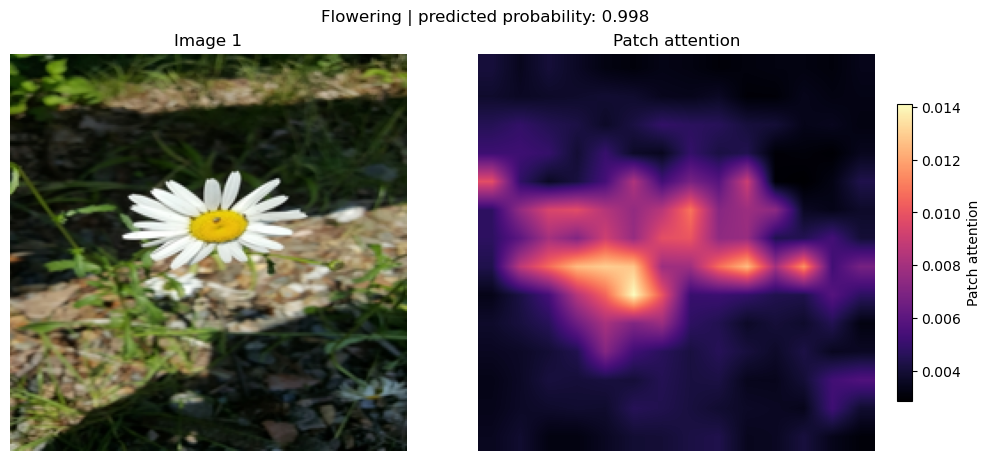

In [32]:
visualize_button.on_click(visualize)
display(visualize_button, visualization_output)
if image_bag is not None:
    show_attention(class_selector.value)